In [1]:
# =============================================================
# Volume Indicator Analysis Notebook
# Based on: docs/volume_indicator.md
# =============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from pathlib import Path

# --- Setup ---
DATA_DIR = Path("../data/ta-data")

def load_ticker(ticker: str) -> pd.DataFrame:
    """Load TA-enriched CSV for a given ticker."""
    csv_path = DATA_DIR / f"{ticker}.csv"
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    return df

# Default: NG.L
ticker = "NG.L"
df = load_ticker(ticker)
df.index = df["Date"]
# --- Filter to last 10 years ---
cutoff_date = pd.Timestamp("2025-10-15")
df = df[df["Date"] >= cutoff_date].reset_index(drop=True)
df.index = df["Date"]

print(f"Loaded {ticker}: {len(df)} rows, {df['Date'].min().date()} → {df['Date'].max().date()}")
print(f"Columns: Close, Volume, ta_obv, ta_cmf, ta_vwap, ta_ema50")

Loaded NG.L: 253 rows, 2025-10-15 → 2026-10-14
Columns: Close, Volume, ta_obv, ta_cmf, ta_vwap, ta_ema50


=== OBV Alignment Summary (Last 10 Years) ===
  Bullish (price↑ + OBV↑)  : 133 days
  Bearish  (price↓ + OBV↓) : 114 days
  Neutral (mixed)          : 6 days

=== OBV Divergence Summary (Last 10 Years) ===
  Bullish Divergence  : 8 signals (early reversal)
  Bearish Divergence  : 14 signals (warning)

Divergence Events (last 10):
      Date  Close       ta_obv obv_divergence
2026-06-01 1184.0 1887742819.0    BULLISH_DIV
2026-06-29 1254.5 2011353258.0    BEARISH_DIV
2026-07-17 1257.0 2006655548.0    BEARISH_DIV
2026-08-10 1175.5 1963156057.0    BULLISH_DIV
2026-08-21 1171.0 1971545249.0    BULLISH_DIV
2026-08-24 1169.5 1961775632.0    BULLISH_DIV
2026-08-27 1160.0 1953960286.0    BULLISH_DIV
2026-10-12 1164.5 1925812004.0    BEARISH_DIV
2026-10-13 1178.5 1935615589.0    BEARISH_DIV
2026-10-14 1185.5 1943607565.0    BEARISH_DIV


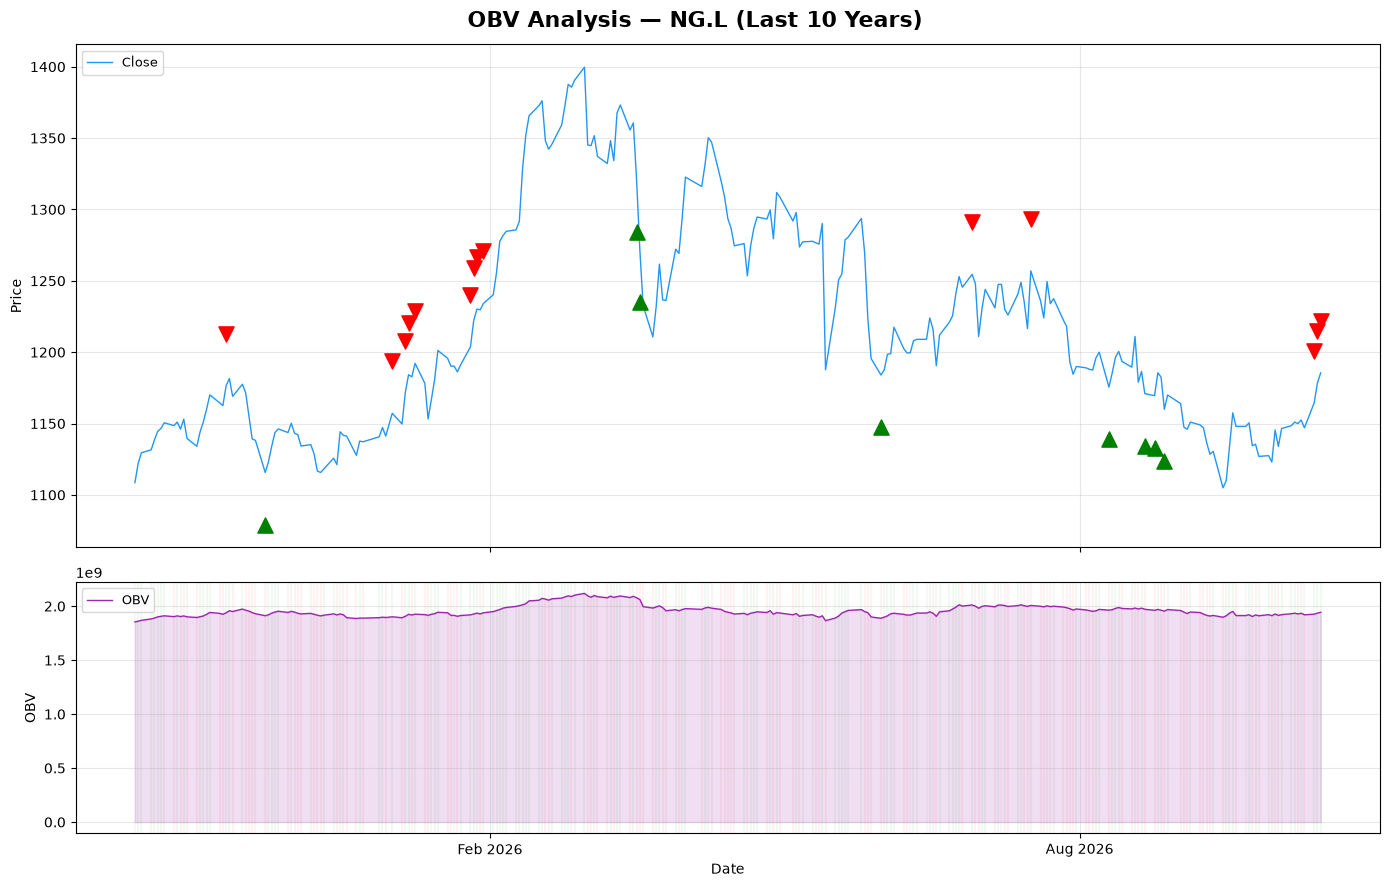

In [2]:
# =============================================================
# 1. OBV (On Balance Volume) Analysis
# =============================================================
# From docs/volume_indicator.md:
#   - Bullish: Price ↑ + OBV ↑ = accumulation
#   - Bearish: Price ↓ + OBV ↓ = distribution
#   - Bullish Divergence: Price lower lows, OBV higher lows → early reversal
#   - Bearish Divergence: Price higher highs, OBV lower highs → warning
# =============================================================

# --- Compute alignment signals ---
price_change = df["Close"].diff()
obv = df["ta_obv"]

df["obv_alignment"] = "NEUTRAL"
df.loc[(price_change > 0) & (obv.diff() > 0), "obv_alignment"] = "BULLISH"
df.loc[(price_change < 0) & (obv.diff() < 0), "obv_alignment"] = "BEARISH"

# --- Detect divergence (20-day rolling swing) ---
window = 20
price_ll = df["Close"].rolling(window).min().shift(1)
price_hh = df["Close"].rolling(window).max().shift(1)
obv_ll = obv.rolling(window).min().shift(1)
obv_hh = obv.rolling(window).max().shift(1)

df["obv_divergence"] = "NONE"
bull_div = (df["Close"] < price_ll) & (obv > obv_ll)
bear_div = (df["Close"] > price_hh) & (obv < obv_hh)
df.loc[bull_div, "obv_divergence"] = "BULLISH_DIV"
df.loc[bear_div, "obv_divergence"] = "BEARISH_DIV"

# --- Summary ---
alignment_counts = df["obv_alignment"].value_counts()
div_counts = df["obv_divergence"].value_counts()

print("=== OBV Alignment Summary (Last 10 Years) ===")
print(f"  Bullish (price↑ + OBV↑)  : {alignment_counts.get('BULLISH', 0)} days")
print(f"  Bearish  (price↓ + OBV↓) : {alignment_counts.get('BEARISH', 0)} days")
print(f"  Neutral (mixed)          : {alignment_counts.get('NEUTRAL', 0)} days")
print()
print("=== OBV Divergence Summary (Last 10 Years) ===")
print(f"  Bullish Divergence  : {div_counts.get('BULLISH_DIV', 0)} signals (early reversal)")
print(f"  Bearish Divergence  : {div_counts.get('BEARISH_DIV', 0)} signals (warning)")
print()

# --- Show divergence events ---
div_events = df[df["obv_divergence"] != "NONE"][["Date", "Close", "ta_obv", "obv_divergence"]]
if len(div_events) > 0:
    print(f"Divergence Events (last 10):")
    print(div_events.tail(10).to_string(index=False))

# --- Chart: Price + OBV ---
fig, axes = plt.subplots(2, 1, figsize=(14, 9),
                          gridspec_kw={"height_ratios": [3, 1.5]},
                          sharex=True)
fig.suptitle(f"OBV Analysis — {ticker} (Last 10 Years)", fontsize=16, fontweight="bold")

# Price chart
ax1 = axes[0]
ax1.plot(df.index, df["Close"], color="#2196F3", linewidth=1, label="Close")
for _, row in div_events.iterrows():
    marker = "^" if row["obv_divergence"] == "BULLISH_DIV" else "v"
    color = "green" if row["obv_divergence"] == "BULLISH_DIV" else "red"
    offset = df["Close"].std() * 0.5
    y = row["Close"] - offset if row["obv_divergence"] == "BULLISH_DIV" else row["Close"] + offset
    ax1.scatter(row["Date"], y, marker=marker, color=color, s=120, zorder=5,
                label=f"{row['obv_divergence']}" if _ == 0 else None)
ax1.set_ylabel("Price")
ax1.legend(loc="upper left", fontsize=9)
ax1.grid(True, alpha=0.3)

# OBV chart
ax2 = axes[1]
ax2.plot(df.index, obv, color="#9C27B0", linewidth=1, label="OBV")
ax2.fill_between(df.index, obv, alpha=0.15, color="#9C27B0")
# Color bars by alignment
for _, row in df.iterrows():
    color = "green" if row["obv_alignment"] == "BULLISH" else "red" if row["obv_alignment"] == "BEARISH" else "gray"
    ax2.axvline(row["Date"], color=color, alpha=0.05)
ax2.set_ylabel("OBV")
ax2.set_xlabel("Date")
ax2.legend(loc="upper left", fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.tight_layout()
plt.show()

=== CMF Signal Summary (Last 10 Years) ===
  STRONG BUY     :    85 days ( 33.6%)
  SELL           :    85 days ( 33.6%)
  BUY            :    56 days ( 22.1%)
  STRONG SELL    :    27 days ( 10.7%)

Latest CMF     : -0.100
Latest Price   : 1185.50
Latest EMA50   : 1163.03
Current Signal : SELL

→ Money is flowing OUT of the stock (distribution)


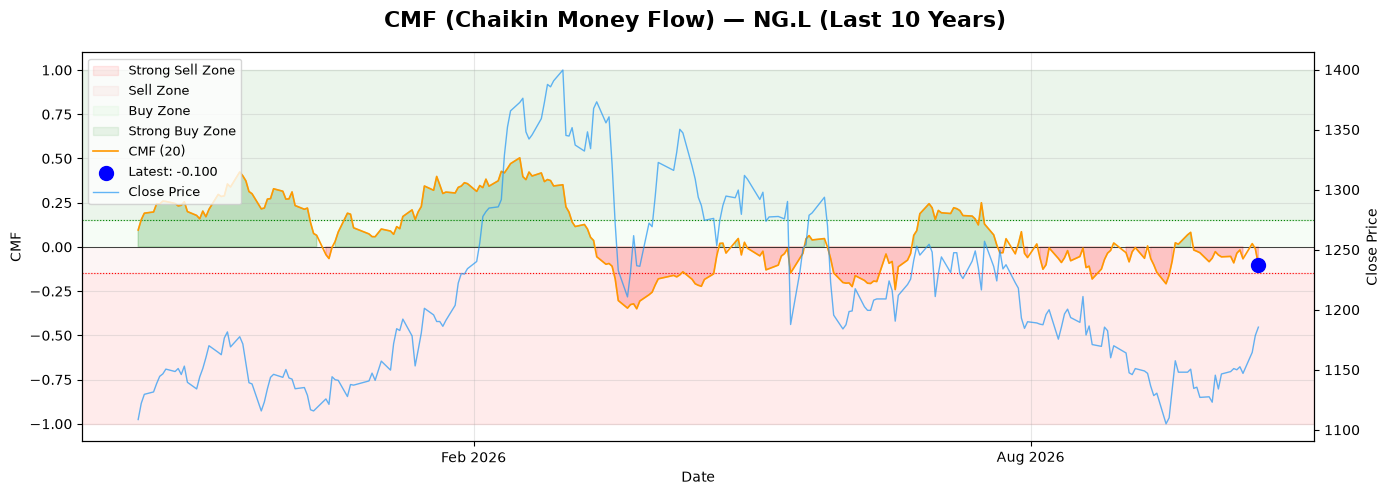

In [3]:
# =============================================================
# 2. CMF (Chaikin Money Flow) Analysis
# =============================================================
# From docs/volume_indicator.md:
#   - CMF range: -1.0 to +1.0
#   - CMF > 0: money flowing in (accumulation)
#   - CMF < 0: money flowing out (distribution)
#   - STRONG BUY: CMF > +0.15 AND Price > EMA50
#   - STRONG SELL: CMF < -0.15 AND Price < EMA50
# =============================================================

cmf = df["ta_cmf"]

# --- Classify signals ---
df["cmf_signal"] = "NEUTRAL"
df.loc[(cmf > 0.15) & (df["Close"] > df["ta_ema50"].fillna(df["Close"])), "cmf_signal"] = "STRONG BUY"
df.loc[(cmf < -0.15) & (df["Close"] < df["ta_ema50"].fillna(df["Close"])), "cmf_signal"] = "STRONG SELL"
df.loc[(cmf > 0) & (df["cmf_signal"] == "NEUTRAL"), "cmf_signal"] = "BUY"
df.loc[(cmf < 0) & (df["cmf_signal"] == "NEUTRAL"), "cmf_signal"] = "SELL"

cmf_counts = df["cmf_signal"].value_counts()

print("=== CMF Signal Summary (Last 10 Years) ===")
for signal, count in cmf_counts.items():
    pct = count / len(df) * 100
    print(f"  {signal:15s}: {count:5d} days ({pct:5.1f}%)")
print()

# --- Show latest CMF value and interpretation ---
latest_cmf = cmf.iloc[-1]
latest_price = df["Close"].iloc[-1]
latest_sma50 = df["ta_ema50"].iloc[-1]
latest_signal = df["cmf_signal"].iloc[-1]

print(f"Latest CMF     : {latest_cmf:.3f}")
print(f"Latest Price   : {latest_price:.2f}")
print(f"Latest EMA50   : {latest_sma50:.2f}")
print(f"Current Signal : {latest_signal}")
print()
if latest_cmf > 0:
    print("→ Money is flowing INTO the stock (accumulation)")
else:
    print("→ Money is flowing OUT of the stock (distribution)")
if latest_signal in ("STRONG BUY", "STRONG SELL"):
    print(f"→ This is a **{latest_signal}** signal")

# --- Chart: CMF with price overlay ---
fig, ax1 = plt.subplots(figsize=(14, 5))
fig.suptitle(f"CMF (Chaikin Money Flow) — {ticker} (Last 10 Years)", fontsize=16, fontweight="bold")

# Background zones
ax1.axhspan(-1.0, -0.15, color="red", alpha=0.08, label="Strong Sell Zone")
ax1.axhspan(-0.15, 0.0, color="lightcoral", alpha=0.08, label="Sell Zone")
ax1.axhspan(0.0, 0.15, color="lightgreen", alpha=0.08, label="Buy Zone")
ax1.axhspan(0.15, 1.0, color="green", alpha=0.08, label="Strong Buy Zone")

ax1.axhline(0, color="black", linewidth=0.5)
ax1.axhline(0.15, color="green", linewidth=0.8, linestyle=":")
ax1.axhline(-0.15, color="red", linewidth=0.8, linestyle=":")

# Fill CMF area
ax1.fill_between(df.index, cmf, 0, where=cmf > 0, alpha=0.2, color="green")
ax1.fill_between(df.index, cmf, 0, where=cmf < 0, alpha=0.2, color="red")
ax1.plot(df.index, cmf, color="#FF9800", linewidth=1.2, label="CMF (20)")

# Mark latest point
ax1.scatter(df.index[-1], latest_cmf, color="blue", s=100, zorder=5, label=f"Latest: {latest_cmf:.3f}")

ax1.set_ylabel("CMF")
ax1.set_xlabel("Date")
ax1.set_ylim(-1.1, 1.1)
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Overlay stock price on secondary y-axis
ax2 = ax1.twinx()
ax2.plot(df.index, df["Close"], color="#2196F3", linewidth=1, alpha=0.7, label="Close Price")
ax2.set_ylabel("Close Price")
lines2, labels2 = ax2.get_legend_handles_labels()
lines1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

=== VWAP Signal Summary (Last 10 Years) ===
  BUY            :   137 days ( 54.2%)
  SELL           :   116 days ( 45.8%)

Price above VWAP  : 54.2%
Price below VWAP  : 45.8%

Latest VWAP  : 1147.16
Latest Close : 1185.50
Price vs VWAP: +3.34%
→ Buyers control the market (price above average transaction price)


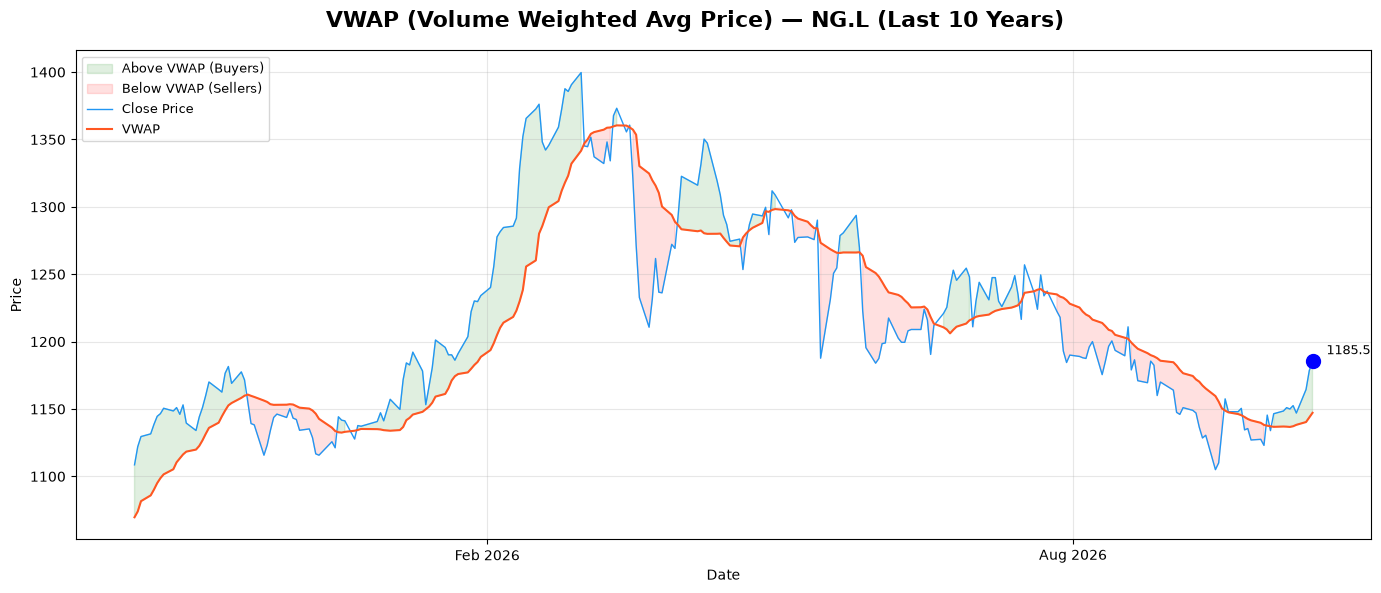

In [4]:
# =============================================================
# 3. VWAP (Volume Weighted Average Price) Analysis
# =============================================================
# From docs/volume_indicator.md:
#   - VWAP = average traded price weighted by volume
#   - Price > VWAP: buyers control → BUY
#   - Price < VWAP: sellers control → SELL
# =============================================================

vwap = df["ta_vwap"]

# --- Classify signals ---
df["vwap_signal"] = "NEUTRAL"
df.loc[df["Close"] > vwap, "vwap_signal"] = "BUY"
df.loc[df["Close"] < vwap, "vwap_signal"] = "SELL"

vwap_counts = df["vwap_signal"].value_counts()

print("=== VWAP Signal Summary (Last 10 Years) ===")
for signal, count in vwap_counts.items():
    pct = count / len(df) * 100
    print(f"  {signal:15s}: {count:5d} days ({pct:5.1f}%)")
print()

# --- Stats ---
pct_above = vwap_counts.get("BUY", 0) / len(df) * 100
pct_below = vwap_counts.get("SELL", 0) / len(df) * 100
print(f"Price above VWAP  : {pct_above:.1f}%")
print(f"Price below VWAP  : {pct_below:.1f}%")

# --- Latest reading ---
latest_vwap = vwap.iloc[-1]
latest_close = df["Close"].iloc[-1]
diff_pct = (latest_close - latest_vwap) / latest_vwap * 100

print()
print(f"Latest VWAP  : {latest_vwap:.2f}")
print(f"Latest Close : {latest_close:.2f}")
print(f"Price vs VWAP: {diff_pct:+.2f}%")
if latest_close > latest_vwap:
    print("→ Buyers control the market (price above average transaction price)")
else:
    print("→ Sellers control the market (price below average transaction price)")

# --- Chart: Price + VWAP ---
fig, ax = plt.subplots(figsize=(14, 6))
fig.suptitle(f"VWAP (Volume Weighted Avg Price) — {ticker} (Last 10 Years)", fontsize=16, fontweight="bold")

# Color the fill between based on signal
buy_mask = df["Close"] >= df["ta_vwap"]
sell_mask = df["Close"] < df["ta_vwap"]
ax.fill_between(df.index, df["Close"], vwap, where=buy_mask, alpha=0.12, color="green", label="Above VWAP (Buyers)")
ax.fill_between(df.index, df["Close"], vwap, where=sell_mask, alpha=0.12, color="red", label="Below VWAP (Sellers)")

ax.plot(df.index, df["Close"], color="#2196F3", linewidth=1, label="Close Price")
ax.plot(df.index, vwap, color="#FF5722", linewidth=1.5, label="VWAP")

# Latest point
ax.scatter(df.index[-1], latest_close, color="blue", s=100, zorder=5)
ax.annotate(f"{latest_close:.1f}", (df.index[-1], latest_close),
            textcoords="offset points", xytext=(10, 5), fontsize=9)

ax.set_ylabel("Price")
ax.set_xlabel("Date")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.tight_layout()
plt.show()

=== OFI Signal Summary (Last 10 Years) ===
  STRONG BUY               :    90 days ( 35.6%)
  STRONG SELL              :    73 days ( 28.9%)
  BUYING PRESSURE          :    46 days ( 18.2%)
  SELLING PRESSURE         :    40 days ( 15.8%)
  NEUTRAL                  :     4 days (  1.6%)

Latest OFI     : 0.179
Latest Price   : 1185.50
Current Signal : BUYING PRESSURE

Mean OFI       : +0.032
OFI std        : 0.504
Skew           : -0.187

-> OFI measures how close the close is to the high/low relative
  to the day's range. Values near +1 mean buyers pushed price
  to the top of the range; values near -1 mean sellers dominated.
  This day's close was mid-range (0.179).


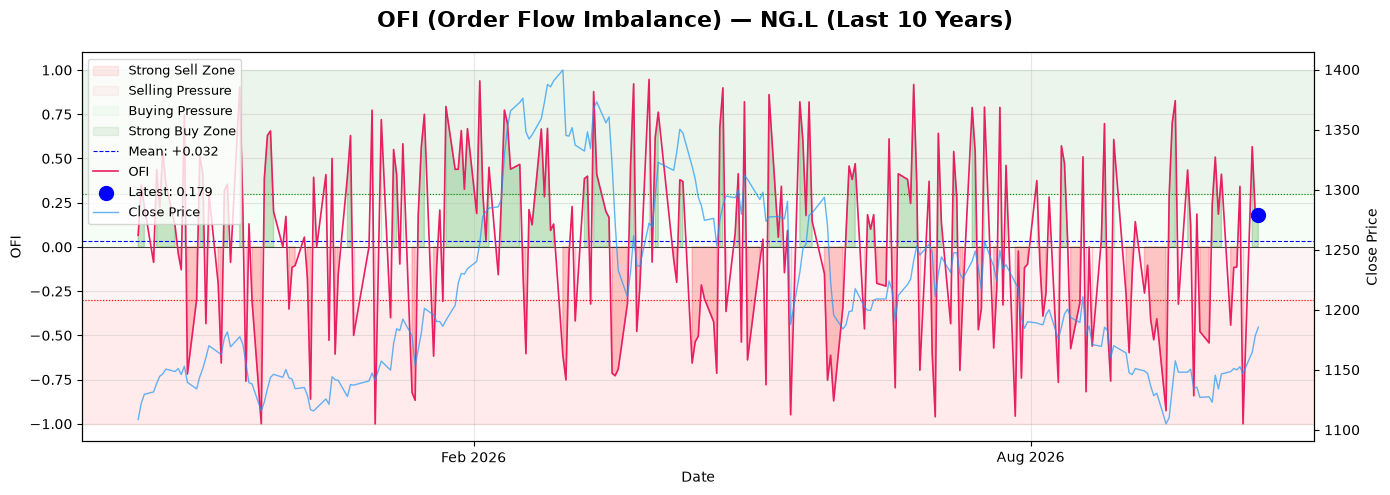

In [5]:
# =============================================================
# 3b. OFI (Order Flow Imbalance) Analysis
# =============================================================
# From calculate_volume.py:
#   - OFI = (Close - Open) / (High - Low)
#   - Range: -1.0 (close at low, sellers won) to +1.0 (close at high, buyers won)
#   - 0.0 = close at open (indecision)
#   - Unlike CMF (which weights by money-flow position), OFI is a
#     pure measure of intraday momentum: where did price finish
#     relative to the full bar range?
# =============================================================

ofi = df["ta_ofi"]

# --- Classify signals ---
df["ofi_signal"] = "NEUTRAL"
df.loc[ofi > 0.3, "ofi_signal"] = "STRONG BUY"
df.loc[ofi < -0.3, "ofi_signal"] = "STRONG SELL"
df.loc[(ofi > 0) & (df["ofi_signal"] == "NEUTRAL"), "ofi_signal"] = "BUYING PRESSURE"
df.loc[(ofi < 0) & (df["ofi_signal"] == "NEUTRAL"), "ofi_signal"] = "SELLING PRESSURE"

ofi_counts = df["ofi_signal"].value_counts()

print("=== OFI Signal Summary (Last 10 Years) ===")
for signal, count in ofi_counts.items():
    pct = count / len(df) * 100
    print(f"  {signal:25s}: {count:5d} days ({pct:5.1f}%)")
print()

# --- Latest OFI value and interpretation ---
latest_ofi_val = ofi.iloc[-1]
latest_price = df["Close"].iloc[-1]
latest_signal = df["ofi_signal"].iloc[-1]

print(f"Latest OFI     : {latest_ofi_val:.3f}")
print(f"Latest Price   : {latest_price:.2f}")
print(f"Current Signal : {latest_signal}")
print()

# --- Distribution stats ---
ofi_mean_val = ofi.mean()
ofi_std_val = ofi.std()
ofi_skew_val = ofi.skew()
print(f"Mean OFI       : {ofi_mean_val:+.3f}")
print(f"OFI std        : {ofi_std_val:.3f}")
print(f"Skew           : {ofi_skew_val:+.3f}")
print()
print("-> OFI measures how close the close is to the high/low relative")
print("  to the day's range. Values near +1 mean buyers pushed price")
print("  to the top of the range; values near -1 mean sellers dominated.")
if latest_ofi_val > 0.5:
    print(f"  This day's close was near the top ({latest_ofi_val:.3f}).")
elif latest_ofi_val < -0.5:
    print(f"  This day's close was near the bottom ({latest_ofi_val:.3f}).")
else:
    print(f"  This day's close was mid-range ({latest_ofi_val:.3f}).")

# --- Chart: OFI with price overlay ---
fig, ax1 = plt.subplots(figsize=(14, 5))
fig.suptitle(f"OFI (Order Flow Imbalance) — {ticker} (Last 10 Years)", fontsize=16, fontweight="bold")

# Background zones
ax1.axhspan(-1.0, -0.3, color="red", alpha=0.08, label="Strong Sell Zone")
ax1.axhspan(-0.3, 0.0, color="lightcoral", alpha=0.08, label="Selling Pressure")
ax1.axhspan(0.0, 0.3, color="lightgreen", alpha=0.08, label="Buying Pressure")
ax1.axhspan(0.3, 1.0, color="green", alpha=0.08, label="Strong Buy Zone")

ax1.axhline(0, color="black", linewidth=0.5)
ax1.axhline(0.3, color="green", linewidth=0.8, linestyle=":")
ax1.axhline(-0.3, color="red", linewidth=0.8, linestyle=":")
ax1.axhline(ofi_mean_val, color="blue", linewidth=0.8, linestyle="--", label=f"Mean: {ofi_mean_val:+.3f}")

# Fill OFI area
ax1.fill_between(df.index, ofi, 0, where=ofi > 0, alpha=0.2, color="green")
ax1.fill_between(df.index, ofi, 0, where=ofi < 0, alpha=0.2, color="red")
ax1.plot(df.index, ofi, color="#E91E63", linewidth=1.2, label="OFI")

# Mark latest point
ax1.scatter(df.index[-1], latest_ofi_val, color="blue", s=100, zorder=5, label=f"Latest: {latest_ofi_val:.3f}")

ax1.set_ylabel("OFI")
ax1.set_xlabel("Date")
ax1.set_ylim(-1.1, 1.1)
ax1.grid(True, alpha=0.3)
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Overlay stock price on secondary y-axis
ax2 = ax1.twinx()
ax2.plot(df.index, df["Close"], color="#2196F3", linewidth=1, alpha=0.7, label="Close Price")
ax2.set_ylabel("Close Price")
lines2, labels2 = ax2.get_legend_handles_labels()
lines1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()


  COMBINED VOLUME DASHBOARD — NG.L (Last 10 Years)

OBV:
  Alignment    : 133 bullish / 114 bearish
  Divergences  : 8 bull-div / 14 bear-div

CMF:
  Latest       : -0.100
  Latest Signal: BUYING PRESSURE

VWAP:
  Latest       : 1147.16
  Price vs VWAP: +3.34%
  Above VWAP   : 54.2% of the time



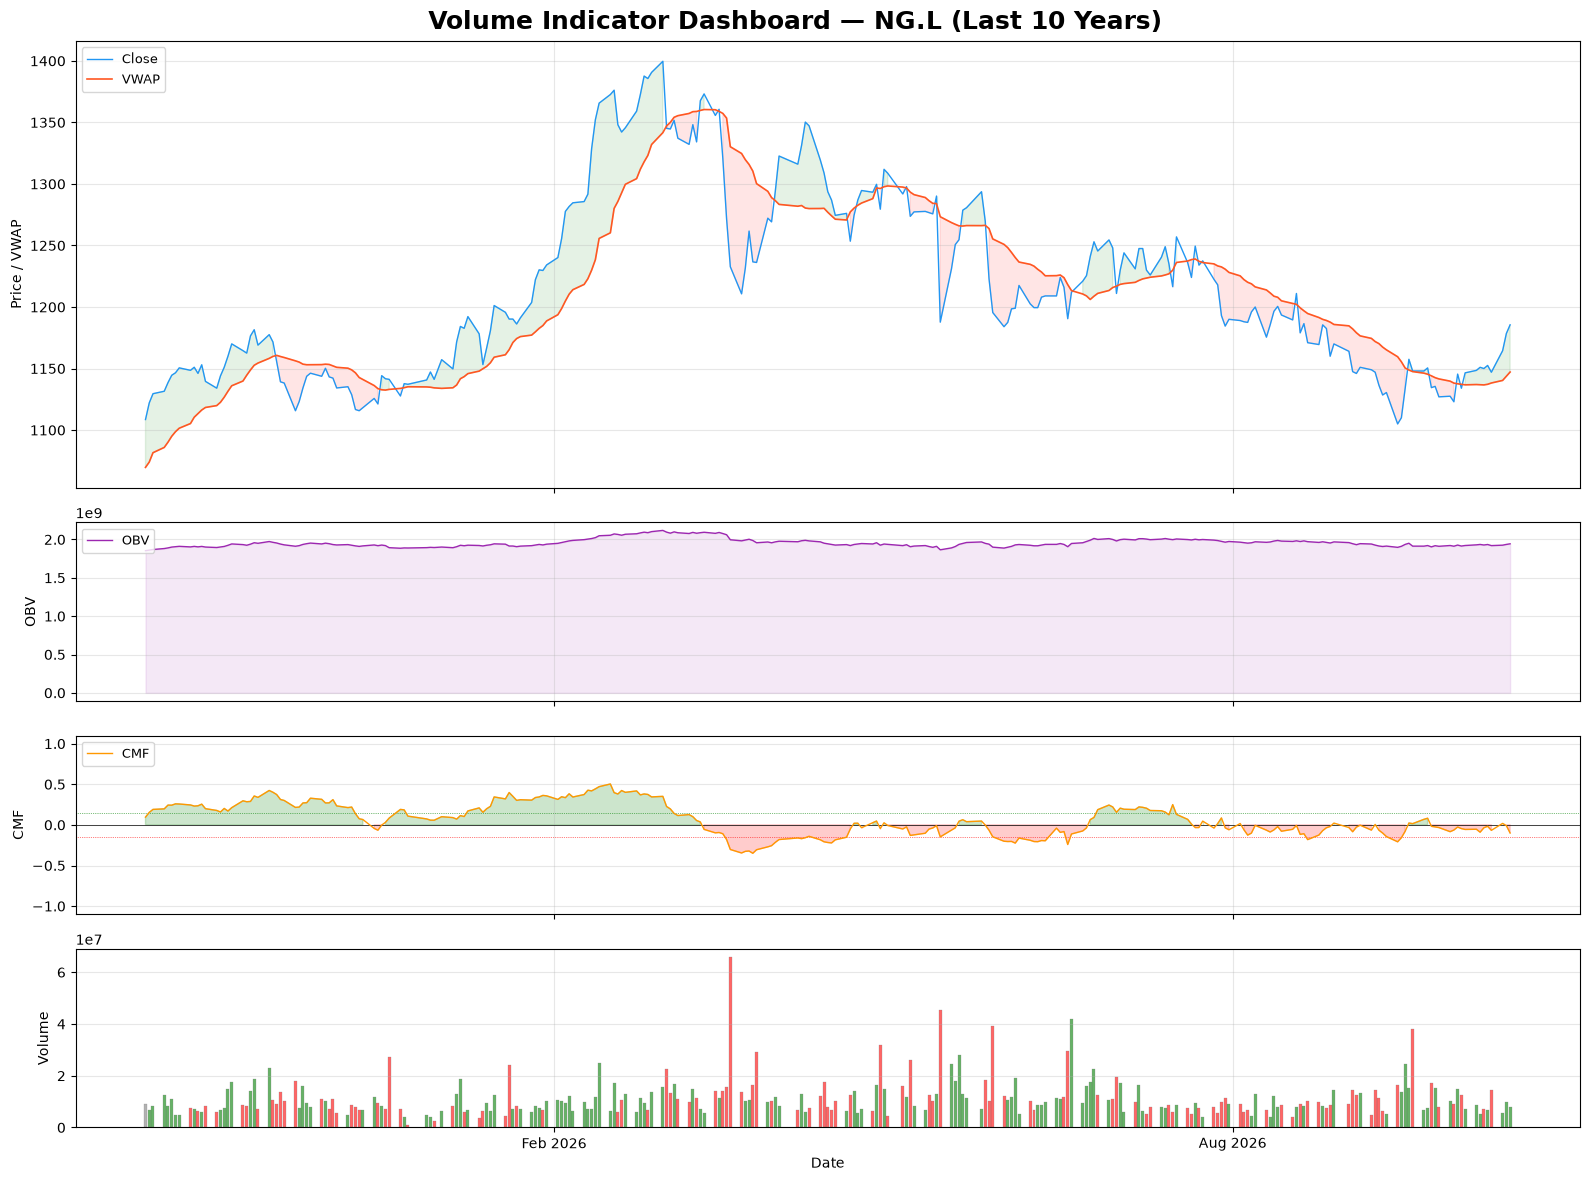

In [6]:
# =============================================================
# 4. Combined Volume Dashboard
# =============================================================
# All three volume indicators together for a complete picture.
# =============================================================

# --- Prepare signal data for dashboard ---
df["vwap_position"] = (df["Close"] - df["ta_vwap"]) / df["ta_vwap"] * 100

# --- Print combined summary ---
print("=" * 60)
print(f"  COMBINED VOLUME DASHBOARD — {ticker} (Last 10 Years)")
print("=" * 60)
print()
print("OBV:")
print(f"  Alignment    : {alignment_counts.get('BULLISH', 0)} bullish / {alignment_counts.get('BEARISH', 0)} bearish")
print(f"  Divergences  : {div_counts.get('BULLISH_DIV', 0)} bull-div / {div_counts.get('BEARISH_DIV', 0)} bear-div")
print()
print("CMF:")
print(f"  Latest       : {latest_cmf:.3f}")
print(f"  Latest Signal: {latest_signal}")
print()
print("VWAP:")
print(f"  Latest       : {latest_vwap:.2f}")
print(f"  Price vs VWAP: {diff_pct:+.2f}%")
print(f"  Above VWAP   : {pct_above:.1f}% of the time")
print()

# --- Combined Dashboard Chart ---
fig, axes = plt.subplots(4, 1, figsize=(16, 12),
                          gridspec_kw={"height_ratios": [3, 1.2, 1.2, 1.2]},
                          sharex=True)
fig.suptitle(f"Volume Indicator Dashboard — {ticker} (Last 10 Years)", fontsize=18, fontweight="bold")

# 1. Price + VWAP
ax1 = axes[0]
ax1.plot(df.index, df["Close"], color="#2196F3", linewidth=1, label="Close")
ax1.plot(df.index, df["ta_vwap"], color="#FF5722", linewidth=1.2, linestyle="-", label="VWAP")
ax1.fill_between(df.index, df["Close"], df["ta_vwap"],
                 where=df["Close"] >= df["ta_vwap"], alpha=0.1, color="green")
ax1.fill_between(df.index, df["Close"], df["ta_vwap"],
                 where=df["Close"] < df["ta_vwap"], alpha=0.1, color="red")
ax1.set_ylabel("Price / VWAP")
ax1.legend(loc="upper left", fontsize=9)
ax1.grid(True, alpha=0.3)

# 2. OBV
ax2 = axes[1]
ax2.plot(df.index, df["ta_obv"], color="#9C27B0", linewidth=1, label="OBV")
ax2.fill_between(df.index, df["ta_obv"], alpha=0.1, color="#9C27B0")
ax2.set_ylabel("OBV")
ax2.legend(loc="upper left", fontsize=9)
ax2.grid(True, alpha=0.3)

# 3. CMF
ax3 = axes[2]
ax3.axhline(0, color="black", linewidth=0.5)
ax3.axhline(0.15, color="green", linewidth=0.5, linestyle=":")
ax3.axhline(-0.15, color="red", linewidth=0.5, linestyle=":")
ax3.fill_between(df.index, cmf, 0, where=cmf > 0, alpha=0.2, color="green")
ax3.fill_between(df.index, cmf, 0, where=cmf < 0, alpha=0.2, color="red")
ax3.plot(df.index, cmf, color="#FF9800", linewidth=1, label="CMF")
ax3.set_ylabel("CMF")
ax3.set_ylim(-1.1, 1.1)
ax3.legend(loc="upper left", fontsize=9)
ax3.grid(True, alpha=0.3)

# 4. Volume
ax4 = axes[3]
colors = ["green" if c >= p else "red" for c, p in zip(df["Close"], df["Close"].shift(1))]
colors[0] = "gray"
ax4.bar(df.index, df["Volume"], color=colors, alpha=0.6, linewidth=0.3, edgecolor="gray")
ax4.set_ylabel("Volume")
ax4.set_xlabel("Date")
ax4.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax4.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()